In [1]:
from IPython.display import HTML

styles = open('library/markdown_style.css').read()
HTML(styles)

# Bike Share Ridership in California
**Author:** Andres Sanchez<br/>
**Data:** 60 months from July 2021 thru June 2026<br/>
**GitHub:** `git@github.com:andrsanc/Bike-Ridership-in-California.git`<br/>

*Benchmark run locally on an Apple Silicon Mac*

# Executive Summary
### How do Californians ride, and how does that differ from one region to the next?
<a id="exec_summary"></a>

This project explores the biking habits of bike-share riders in Southern and Northern California, looking to uncover seasonal rhythms, regional differences, and the factors that drive ridership, using a full toolkit of classical and Bayesian statistical inference.

Public investment in cycling infrastructure has accelerated in recent years, and Los Angeles County offers a clear example. Since 2012, [LA County Public Works][1] has completed 41 projects to improve biking conditions, adding more than 75 miles of new construction, with many more projects planned or under way. These investments are part of a broader effort to reduce the region’s dependence on cars by creating better roads for cyclists and making riding safer for everyone.

Against this backdrop, the project examines how Californians use bike share programs and compares usage in Southern California with that in Northern California and across the state as a whole. By analyzing when, where, and for how long people ride, the analysis asks whether bike share serves different purposes in different regions, whether as a commuting tool, a connector to public transit, or a recreational activity. It also considers what those differences imply for where future investment in cycling infrastructure is likely to be most effective.

[1]: https://pw.lacounty.gov/tpp/bike/index.cfm?action=projects&CFID=73153822&CFTOKEN=6d74aa096542fc89-E8F5981C-BBE2-885E-EA394C55251D9130

In [2]:
use_raw_data = True

In [3]:
if use_raw_data:
    data_prefix = 'data/raw/'
else:
    data_prefix = 'data/sample/'

print(data_prefix)

data/raw/


In [4]:
import math, os, requests, time, folium, io, random, re, html
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# For consistent plot formatting
title_font_dict = {'fontsize': 10,
                   'color': '#A51C30',
                   'fontweight': 'bold'}
title_large_font_dict = {'fontsize': 14,
                         'color': '#A51C30',
                         'fontweight': 'bold'}
axis_font_dict = {'color': '#A51C30',
                  'fontweight': 'bold'}

exec(open('library/helpers.py').read())
%whos function

Variable                      Type        Data/Info
---------------------------------------------------
bs_strat_fun                  function    <function bs_strat_fun at 0x11b337420>
county_geo_fun                function    <function county_geo_fun at 0x11b336d40>
distance_fun                  function    <function distance_fun at 0x11b336b60>
eda_bar_fun                   function    <function eda_bar_fun at 0x11b337240>
eda_hist_fun                  function    <function eda_hist_fun at 0x11b336f20>
eda_scatter_fun               function    <function eda_scatter_fun at 0x11b337060>
eda_violin_fun                function    <function eda_violin_fun at 0x11b336fc0>
federal_holiday_fun           function    <function federal_holiday_fun at 0x11b336de0>
iqr_fun                       function    <function iqr_fun at 0x11b336e80>
missing_coord_fun             function    <function missing_coord_fun at 0x11b336c00>
model_coeff_fun               function    <function model_coeff_fun at 0x

# Notebook contents
<a id="contents"></a>

[**Executive Summary**](#exec_summary)<br/>

[**Southern California Data**](#socal)<br/>
**Dataset Details:** Import 20 quarterly files and a station information file. Station file includes neighboorhood data.
  - [Bike Station](#socal_station)
  - [Trip Data](#socal_data)
  - [Impute Missing Data](#socal_impute)

[**Northern California Data**](#norcal)<br/>
**Dataset Details:** Import 60 monthly files and and geometry file that includes county boundaries.
  - [County Boundaries](#norcal_county)
  - [Trip Data](#norcal_data)
  - [Impute Missing Data](#norcal_impute)

[**Consolidate Data**](#consolidate)<br/>
Consolidate Northern and Southern California data into one dataframe.
  - [Data Dictionary](#dictionary)
  - [Feature Engineering](#fe)
  - [Save Consolidated Data](#save)

[**References**](#ref)<br/>

# Southern California Data
<a id="socal"></a>

Los Angeles Metro, and its partners in nearby cities, operate **Metro Bike Share** and make the [data][1] available to the public. For this project, I downloaded quarterly files from 2017Q1 thru 2026Q2 as well as a file with [current][2] and [historical][3] station information which was used to impute some missing information.

[1]: https://bikeshare.metro.net/about/data/
[2]: https://bikeshare.metro.net/wp-content/uploads/2026/07/metro-bike-share-stations-2026-07-15.csv
[3]: https://bikeshare.metro.net/wp-content/uploads/2024/01/metro-bike-share-stations-2024-01-01.csv

[Return to contents](#contents)

## Bike Station Information
<a id="socal_station"></a>

Data quality review at the station level identified several issues, which were addressed as follows.

Station 4682, located in the Downtown region, lacked a region assignment. The missing value was imputed manually. Station 4649 was recorded with a longitude of the wrong sign, which placed it far from its true location. This error was corrected manually.

Station 3000 is a virtual station that staff use, for special events, when a bike cannot otherwise be checked in or out at a physical station. Because it does not represent a physical location, the station was excluded from the data. Stations 4285 and 4286, which correspond to the Metro Bike Share Free Bikes, do not include coordinates, so distance and speed cannot be estimated for their trips. These stations were also excluded.

[Return to contents](#contents)

In [5]:
mta_station_files = ['metro-bike-share-stations-2024-01-01.csv',
                     'metro-bike-share-stations-2026-07-15.csv']
mta_types_d = {'station_id': str,
               'station_name': str,
               'station_date': 'datetime64[ns]',
               'station_region': str,
               'station_status': str,
               'station_lat': float,
               'station_lon': float}
mta_cols = [keys for keys, types in mta_types_d.items()]

mta_station_df = pd.DataFrame(columns = mta_cols).astype(mta_types_d)
for f in mta_station_files:
    df = pd.read_csv('data/' + f, 
                     names = mta_cols,
                     parse_dates = ['station_date'],
                     skiprows = 1)
    mta_station_df = pd.concat([mta_station_df, 
                                df[~df['station_id'].isin(mta_station_df['station_id'])]]).reset_index(drop = True)

# Clean up
socal_exclude_id = ['3000', '4285', '4286']
mta_station_df['station_id'] = mta_station_df['station_id'].astype(str)
mta_station_df = mta_station_df[~mta_station_df['station_id'].isin(socal_exclude_id)].reset_index(drop = True)
mta_station_df.loc[mta_station_df['station_id'] == '4682', 'station_region'] = 'DTLA'
mta_station_df.loc[mta_station_df['station_id'] == '4649', 'station_lon'] = -mta_station_df['station_lon']

mta_station_df

,station_id,station_name,station_date,station_region,station_status,station_lat,station_lon
0,3005,7th & Flower,2016-07-07,DTLA,Active,34.048500,-118.258537
1,3006,Olive & 8th,2016-07-07,DTLA,Active,34.045540,-118.256668
2,3007,5th & Grand,2016-07-07,DTLA,Active,34.050480,-118.254593
3,3008,Figueroa & 9th,2016-07-07,DTLA,Active,34.046612,-118.262733
4,3010,11th & Maple,2016-07-10,DTLA,Active,34.037048,-118.254868
...,...,...,...,...,...,...,...
446,4736,Wilshire & La Cienega D Line Station,2026-05-08,DTLA,Active,34.065571,-118.375862
447,4737,CicLAvia - West LA Santa Monica Hub,2026-04-26,Westside,Inactive,34.038849,-118.467018
448,4739,Fairfax & 3rd,2026-06-18,DTLA,Inactive,34.071339,-118.361542
449,4740,Downtown Santa Monica E Line Station (South),2026-06-23,Westside,Active,34.013321,-118.491364


In [6]:
mta_station_df.isnull().sum()

station_id        0
station_name      0
station_date      0
station_region    0
station_status    0
station_lat       0
station_lon       0
dtype: int64

## Trip Data
<a id="socal_data"></a>

20 quarterly files were downloaded. These encompass the most recent 5 years period available, from 2021 Q3 thru 2026 Q2. Missing coordinates were imputed from station information.

As mentioned earlier, Station 4649 was recorded with a longitude of the wrong sign, which places it far from its true location. This error was corrected manually.

[Return to contents](#contents)

In [7]:
socal_prefix = data_prefix + 'southern/'

socal_files = sorted([socal_prefix + f for f in os.listdir(socal_prefix) if '.csv' in f])
print(str(len(socal_files)), "quarterly files available")

socal_files[0:5]

20 quarterly files available


['data/raw/southern/metro-trips-2021-q3.csv',
 'data/raw/southern/metro-trips-2021-q4.csv',
 'data/raw/southern/metro-trips-2022-q1.csv',
 'data/raw/southern/metro-trips-2022-q2.csv',
 'data/raw/southern/metro-trips-2022-q3.csv']

In [8]:
socal_df = pd.DataFrame()

for f in socal_files:
    df = pd.read_csv(f, 
                     dtype = str,
                     parse_dates = ['start_time', 'end_time'])
    for c in ['start_station', 'end_station']:
        df = df.rename(columns = {c: c + '_id'})
    df = df.rename(columns = {'duration': 'duration_min'})
    for c in ['start_lat', 'start_lon', 'end_lat', 'end_lon']:
        df[c] = df[c].astype(float)
    for c in ['plan_duration', 'duration_min']:
        df[c] = df[c].astype(int)
    socal_df = pd.concat([socal_df, df], ignore_index = True)
del df

socal_df['cal_region'] = 'SoCal'
socal_df = socal_df[~socal_df['start_station_id'].isin(socal_exclude_id)].reset_index(drop = True)
socal_df = socal_df[~socal_df['end_station_id'].isin(socal_exclude_id)].reset_index(drop = True)
socal_df = socal_df.drop(['bike_id', 'plan_duration'], axis = 1)
socal_df.loc[socal_df['start_station_id'] == '4649', 'start_lon'] = -socal_df['start_lon']
socal_df.loc[socal_df['end_station_id'] == '4649', 'end_lon'] = -socal_df['end_lon']

socal_df.isnull().sum()

trip_id                  0
duration_min             0
start_time               0
end_time                 0
start_station_id         0
start_lat                0
start_lon                0
end_station_id           0
end_lat                  0
end_lon                  2
trip_route_category      0
passholder_type        534
bike_type                0
cal_region               0
dtype: int64

## Append SoCal regions and impute missing data
<a id="socal_impute"></a>

Where coordinates were missing, they were appended by matching on the station identifier, using the known location of each station.

To merge the Southern California data with the Northern California data, the **passholder_type** variable was mapped to **user_type**, the harmonized field used across both regions. A small number of records (0.02%) had a missing **passholder_type** or a value indicating a test entry. These records were excluded for consistency with the Northern California data, which contain no equivalent category.

The Northern California data contain only two values of **bike_type**, standard and electric. A small number of records (0.01%) coded as smart bikes fall outside the scope of this analysis and were excluded, which ensures that bike types are comparable across the two regions.

[Return to contents](#contents)

In [9]:
socal_df = missing_coord_fun(socal_df, mta_station_df, 'start')
socal_df = missing_coord_fun(socal_df, mta_station_df, 'end')
socal_df['user_type'] = socal_df['passholder_type'].map({'Monthly Pass': 'member', 
                                                         'Annual Pass': 'member', 
                                                         'Walk-up': 'casual',
                                                         'One Day Pass': 'casual'})
socal_df = socal_df[socal_df['user_type'].isin(['member', 'casual'])].reset_index(drop = True)
socal_df = socal_df[socal_df['bike_type'].isin(['standard', 'electric'])].reset_index(drop = True)

socal_df.isnull().sum()

trip_id                0
duration_min           0
start_time             0
end_time               0
start_station_id       0
start_lat              0
start_lon              0
end_station_id         0
end_lat                0
end_lon                0
trip_route_category    0
passholder_type        0
bike_type              0
cal_region             0
start_region           0
end_region             0
user_type              0
dtype: int64

In [10]:
socal_station_df = station_coord_fun(socal_df)

socal_color_map = {'DTLA': 'black',
                   'Port of LA': 'green',
                   'North Hollywood': 'orange',
                   'Pasadena': 'blue',
                   'Westside': 'red'}

station_plot_fun(socal_station_df, lat = 'station_lat', lon = 'station_lon', w = 600, h = 400, z = 10, cm = socal_color_map)

In [11]:
print('Southern California data contains ' + format(socal_df.shape[0], ',.0f') + ' bike trips from ' +
      format(socal_df['start_time'].min(), '%B %d, %Y') + ' thru ' + format(socal_df['start_time'].max(), '%B %d, %Y') + '\n')

Southern California data contains 1,952,578 bike trips from July 01, 2021 thru June 30, 2026



# Northern California Data
<a id="norcal"></a>

**Lyft Bike** operates the bike sharing program in Northern California and makes the [data][1] available to the public. For this project, I downloaded monthly files from July 2017 thru June 2026 in order to align with Southern California data.

[1]: https://lyftbikes.com/system-data

[Return to contents](#contents)

## County Boundaries
<a id="norcal_county"></a>

To align spatial granularity across datasets, administrative county [boundaries][1] sourced from the **SF Open Data** repository are utilized to construct regional classifications, thereby reconciling the geographic schema with the regional stratification included in the Southern California dataset.

[1]: https://data.sf.gov/Geographic-Locations-and-Boundaries/Bay-Area-Counties/s9wg-vcph

[Return to contents](#contents)

In [12]:
norcal_counties = gpd.read_file('data/bay_area_county_polygons_20261004.geojson')[['county', 'geometry']]
norcal_counties

,county,geometry
0,Alameda,"MULTIPOLYGON (((-122.21496 37.76113, -122.2156..."
1,Contra Costa,"MULTIPOLYGON (((-121.95091 38.05392, -121.9505..."
2,Marin,"MULTIPOLYGON (((-122.86959 38.0214, -122.87116..."
3,Napa,"MULTIPOLYGON (((-122.20246 38.68898, -122.2023..."
4,San Francisco,"MULTIPOLYGON (((-122.47738 37.81103, -122.4763..."
5,San Mateo,"MULTIPOLYGON (((-122.50248 37.70813, -122.4977..."
6,Santa Clara,"MULTIPOLYGON (((-122.02427 37.46094, -122.0203..."
7,Solano,"MULTIPOLYGON (((-122.01053 38.0929, -122.01104..."
8,Sonoma,"MULTIPOLYGON (((-123.53354 38.76841, -123.5333..."


## Trip Data
<a id="norcal_data"></a>

60 monthly files were downloaded. These encompass data from July 2021 thru June 2026 to match the Southern California data.

[Return to contents](#contents)

In [13]:
norcal_prefix = data_prefix + 'northern/'

norcal_files = sorted([norcal_prefix + f for f in os.listdir(norcal_prefix) if '.csv' in f])
print(str(len(norcal_files)), "monthly files available")

norcal_files[0:5]

60 monthly files available


['data/raw/northern/202107-baywheels-tripdata.csv',
 'data/raw/northern/202108-baywheels-tripdata.csv',
 'data/raw/northern/202109-baywheels-tripdata.csv',
 'data/raw/northern/202110-baywheels-tripdata.csv',
 'data/raw/northern/202111-baywheels-tripdata.csv']

In [14]:
norcal_cols = {'ride_id': 'trip_id',
               'rideable_type': 'bike_type',
               'started_at': 'start_time',
               'ended_at': 'end_time',
               'start_station_name': 'start_station_name',
               'start_station_id': 'start_station_id',
               'end_station_name': 'end_station_name',
               'end_station_id': 'end_station_id',
               'start_lat': 'start_lat',
               'start_lng': 'start_lon',
               'end_lat': 'end_lat',
               'end_lng': 'end_lon',
               'member_casual': 'user_type'}

norcal_df = pd.DataFrame()

for f in norcal_files:
    df = pd.read_csv(f, dtype = str)
    df.columns = [norcal_cols[c] for c in df.columns]
    df['bike_type'] = df['bike_type'].str.replace('_bike', '')
    for c in ['start_time', 'end_time']:
        df[c] = pd.to_datetime(df[c], format = 'ISO8601')
    df['duration_min'] =  round((df['end_time'] - df['start_time']).dt.total_seconds() / 60)
    df['duration_min'] = df['duration_min'].astype(int)
    for c in ['start_lat', 'start_lon', 'end_lat', 'end_lon']:
        df[c] = df[c].astype(float)
    for c in ['start_station_name', 'end_station_name', 'duration_sec']:
        if c in df.columns:
            df = df.drop([c], axis = 1)    
    norcal_df = pd.concat([norcal_df, df], ignore_index = True)
del df

norcal_df['cal_region'] = 'NorCal'
norcal_df.isnull().sum() / norcal_df.shape[0]

trip_id             0.000000
bike_type           0.000000
start_time          0.000000
end_time            0.000000
start_station_id    0.101079
end_station_id      0.115539
start_lat           0.000000
start_lon           0.000000
end_lat             0.000564
end_lon             0.000564
user_type           0.000000
duration_min        0.000000
cal_region          0.000000
dtype: float64

## Append NorCal regions and impute missing data
<a id="norcal_impute"></a>

A small proportion of records (0.06%) lack both end coordinates and an end station identifier, which makes it impossible to impute the missing coordinates. These records were therefore excluded from the analysis.

A substantial minority of records (approximately 10%) lack a station identifier yet retain partial coordinates. In these cases, the missing station is typically accompanied by truncated coordinate values. Such irregularities indicate that the coordinates are unreliable for estimating trip distance and speed. Accordingly, these records are classified as round trips: they are excluded from all speed and distance analyses but retained for the remaining analyses. 

Inspection of the spatial distribution of bike stations reveals that ridership is heavily concentrated in three counties: San Francisco, Alameda, and Santa Clara. Trips originating outside these counties account for only 1.1% of the data. Because the present analysis focuses on regional and local variation, and because these three counties together contribute more than 16 million trips, we restrict the sample to trips occurring within them and exclude all others.

The Southern California data contain only two values of **bike_type**, standard and electric. A small number of records (0.12%) coded as docked bikes or electric scooters fall outside the scope of this analysis and were excluded.

The Southern California data also include a variable, **trip_route_category**, which takes the value One Way or Round Trip. Because the Northern California data do not contain this field, it was constructed for all records by comparing the starting and ending coordinates and station identifiers: a trip was classified as a Round Trip when these matched and as One Way otherwise.

[Return to contents](#contents)

In [15]:
# Append regions
norcal_df = county_geo_fun(norcal_df, latc = 'start_lat', lonc = 'start_lon', geodf = norcal_counties)
norcal_df['start_region'] = norcal_df['station_region'].fillna('Unknown')
norcal_df = norcal_df.drop(['station_region'], axis = 1)
norcal_df = county_geo_fun(norcal_df, latc = 'end_lat', lonc = 'end_lon', geodf = norcal_counties)
norcal_df['end_region'] = norcal_df['station_region'].fillna('Unknown')
norcal_df = norcal_df.drop(['station_region'], axis = 1)

# Exclude bad records
norcal_df = norcal_df[((norcal_df['end_station_id'].isnull()) & 
                       (norcal_df['end_lat'].isnull()) & 
                       (norcal_df['end_lon'].isnull())) == False].reset_index(drop = True)
norcal_df = norcal_df[(norcal_df['start_lat'] == 0) & (norcal_df['start_lat'] == 0) == False].reset_index(drop = True)
norcal_df = norcal_df[(norcal_df['end_lat'] == 0) & (norcal_df['end_lon'] == 0) == False].reset_index(drop = True)

# Remove bike stations in New York and Long Beach
for s in ['Lab - NYC - Monolith', 'LB-562']:
    norcal_df = norcal_df[((norcal_df['start_station_id'] == s) | (norcal_df['end_station_id'] == s)) == False].reset_index(drop = True)

# Impute missing station ids
for c in ['start_station_id', 'end_station_id']:
    norcal_df[c] = norcal_df[c].fillna('Unknown')

# Map bike_type
norcal_df.loc[norcal_df['bike_type'] == 'classic', 'bike_type'] = 'standard'
norcal_df = norcal_df[norcal_df['bike_type'].isin(['standard', 'electric'])].reset_index(drop = True)

# Add trip_route_category
norcal_coords = zip(norcal_df['start_lat'], norcal_df['start_lon'],
                    norcal_df['end_lat'], norcal_df['end_lon'])
norcal_df['trip_route_category'] = ['Round Trip' if distance_fun(lat1, lon1, lat2, lon2) == 0 
                                    else 'One Way' for lat1, lon1, lat2, lon2 in norcal_coords]
norcal_df.loc[norcal_df['start_station_id'] == norcal_df['end_station_id'], 'trip_route_category'] = 'Round Trip'
norcal_df.loc[norcal_df['start_station_id'] == 'Unknown', 'trip_route_category'] = 'Round Trip'
norcal_df.loc[norcal_df['end_station_id'] == 'Unknown', 'trip_route_category'] = 'Round Trip'

norcal_df.isnull().sum()

trip_id                0
bike_type              0
start_time             0
end_time               0
start_station_id       0
end_station_id         0
start_lat              0
start_lon              0
end_lat                0
end_lon                0
user_type              0
duration_min           0
cal_region             0
start_region           0
end_region             0
trip_route_category    0
dtype: int64

In [16]:
norcal_station_df = station_coord_fun(norcal_df)

norcal_color_map = {'Alameda': 'black',
                    'Contra Costa': 'green',
                    'Marin': 'orange',
                    'San Francisco': 'blue',
                    'San Mateo': 'red',
                    'Santa Clara': 'purple',
                    'Unknown': 'grey'}

station_plot_fun(norcal_station_df, lat = 'station_lat', lon = 'station_lon', w = 600, h = 400, z = 8, cm = norcal_color_map)

In [17]:
norcal_counties_inc = ['San Francisco', 'Alameda', 'Santa Clara']

for c in ['start_region', 'end_region']:
    norcal_df = norcal_df[norcal_df[c].isin(norcal_counties_inc)].reset_index(drop = True)

In [18]:
print('Northern California data contains ' + format(norcal_df.shape[0], ',.0f') + ' bike trips from ' +
      format(norcal_df['start_time'].min(), '%B %d, %Y') + ' thru ' + format(norcal_df['start_time'].max(), '%B %d, %Y') + '\n')

Northern California data contains 16,732,612 bike trips from July 01, 2021 thru June 30, 2026



# Consolidate data
<a id="consolidate"></a>
Now that Northern and Southern California files have been prepared we can consolidate them into one dataframe and add new features. At the end of this section, we will save the consolidated dataset to avoid re-processing data in future sections if needed.

[Return to contents](#contents)

In [19]:
bike_df = pd.concat([socal_df.drop(['passholder_type'], axis = 1), norcal_df]).reset_index(drop = True)

# Change case for consistency
for c in ['bike_type', 'user_type']:
    bike_df[c] = bike_df[c].str.title()

# Reorder columns
bike_df = bike_df[['trip_id', 'cal_region', 'trip_route_category', 'bike_type', 'user_type', 'start_time', 'end_time', 'duration_min',
                   'start_station_id', 'end_station_id', 'start_region', 'end_region', 'start_lat', 'start_lon', 'end_lat', 'end_lon']]

## Data dictionary:
<a id="dictionary"></a>
- **trip_id:** A unique identifier for each bike trip.
- **cal_region:** The region within the state of California: Northern (**NorCal**) or Southern California (**SoCal**).
- **trip_route_category:** The type of trip: **Round Trip** or **One Way**.
- **bike_type:** The type of bike used: **Standard** or **Electric**.
- **user_type:** The type of bike user: Subscriber (**Member**) of a bike sharing program or a one time user (**Casual**).
- **start_time** and **end_time:** Date and time for the start and end of a trip. Northern California timestamp includes seconds but Southern California data is truncated to the minute.
- **duration_min:** The duration of a bike trip expressed in minutes for consistency across regions.
- **start_station_id** and **end_station_id:** A unique identifier for each bike station where users can pick up and return a bike.
- **start_region** and **end_region:** The name of the local regions in the dataset. Northern California data broken down by counties, while Southern California data broken down by participating MTA cities.
- **start_lat, start_lon, end_lat** and **end_lon:** The geographic coordinates for the start and end of a trip.

[Return to contents](#contents)

In [20]:
bike_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18685190 entries, 0 to 18685189
Data columns (total 16 columns):
 #   Column               Dtype         
---  ------               -----         
 0   trip_id              str           
 1   cal_region           str           
 2   trip_route_category  str           
 3   bike_type            str           
 4   user_type            str           
 5   start_time           datetime64[us]
 6   end_time             datetime64[us]
 7   duration_min         int64         
 8   start_station_id     str           
 9   end_station_id       str           
 10  start_region         str           
 11  end_region           str           
 12  start_lat            float64       
 13  start_lon            float64       
 14  end_lat              float64       
 15  end_lon              float64       
dtypes: datetime64[us](2), float64(4), int64(1), str(9)
memory usage: 2.2 GB


## Feature Engineering
<a id="fe"></a>

Trips with a recorded duration of zero were removed from the dataset, as these cannot be classified as actual bike trips.

**Feature Engineering:**
1. **Holiday** indicator: a binary variable denoting whether a trip occurred on a U.S. federal holiday.
2. **Date_Month**: Year and month when the trip occured.
3. **Trip Distance**: the straight-line distance between the starting and ending coordinates. This was calculated only for one-way trips, because the starting and ending coordinates of round trips are identical.
4. **Trip Speed**: the estimated average speed of a trip, expressed in miles per hour.
5. **Hour**: the hour at which the trip began, expressed as an integer from 0 to 23.
6. **Hour Block**: 4-hour blocks of the hour during which the trip began.
7. **Weekday Number**: expressed as an integer from 0 to 6, where Monday = 0.
8. **Weekend** indicator: a binary variable equal to 0 for trips beginning Monday through Friday and 1 for trips beginning Saturday or Sunday.
9. **Month**: expressed as an integer from 1 to 12.
10. **Quarter**: expressed as an integer from 1 to 4, where January through March = 1.
11. **Bike Year**: the year in which a trip took place, defined as July through June of the following year rather than January through December, so every bike year in the dataset spans exactly 12 months.
12. **Duration Min Log**: Logarithmic transformation of Trip Duration (Minutes).
13. **Trip Distance Log**: Logarithmic transformation of Trip Distance.

**Outlier Removal**
1. Trips with a duration longer than 2 hours (0.6327% of trips) were removed.
2. Trips with an estimated average speed greater than 20 mph (0.0101% of trips) were removed.
3. One way trips with no distance (0.0002% of trips) were removed.
4. Round trips returned (1.1% of trips) within 1 minute are suspected to be invalid trips and were removed. A look at the distribution shows a bimodal distribution with the first mode at 1 minute so a decision was made to remove these trips as the user likely changed their mind and returned the bike.

[Return to contents](#contents)

In [21]:
# Remove invalid trips
bike_df = bike_df[bike_df['duration_min'] >= 1].reset_index(drop = True)

# Federal Holidays and year and month of trip
bike_df['date'] = pd.to_datetime(bike_df['start_time'].dt.date)
bike_df = federal_holiday_fun(bike_df)
bike_df['date_month'] = bike_df['date'].dt.to_period('M').dt.to_timestamp()

# Trip Distance, Average Speed not availale for Round Trips
bike_coords = zip(bike_df['start_lat'], bike_df['start_lon'], bike_df['end_lat'], bike_df['end_lon'])
bike_df['trip_distance'] = [distance_fun(lat1, lon1, lat2, lon2) for lat1, lon1, lat2, lon2 in bike_coords]
bike_df['trip_speed'] = bike_df['trip_distance'] / bike_df['duration_min'] * 60
for c in ['trip_distance', 'trip_speed']:
    bike_df.loc[bike_df['trip_route_category'] == 'Round Trip', c] = np.nan
bike_df['trip'] = 1 

# Hour of trip, day of the week, month and quarter
bike_df['hour'] = bike_df['start_time'].dt.hour
bike_df.loc[bike_df['hour'].isin([0, 1, 2, 3]), 'hour_block'] = 'Overnight'
bike_df.loc[bike_df['hour'].isin([4, 5, 6, 7]), 'hour_block'] = 'Early Morning'
bike_df.loc[bike_df['hour'].isin([8, 9, 10, 11]), 'hour_block'] = 'Morning'
bike_df.loc[bike_df['hour'].isin([12, 13, 14, 15]), 'hour_block'] = 'Midday'
bike_df.loc[bike_df['hour'].isin([16, 17, 18, 19]), 'hour_block'] = 'PM Peak'
bike_df.loc[bike_df['hour'].isin([20, 21, 22, 23]), 'hour_block'] = 'Late Evening'
bike_df['weekday_num'] = bike_df['start_time'].dt.day_of_week
bike_df['weekend'] = [int(d >= 5) for d in bike_df['weekday_num']]
bike_df['month'] = bike_df['start_time'].dt.month
bike_df['quarter'] = bike_df['date'].dt.quarter 
bike_df['bike_year'] = [d.year + 1 if d.month >= 7 else d.year for d in bike_df['date']]

# Log transformations
for c in ['duration_min', 'trip_distance']:
    bike_df[c + '_log'] = np.log1p(bike_df[c]) 

In [22]:
# Remove Outliers
max_duration = 120
max_speed = 20

print('Outliers:')
print('Trips with duration longer than ' + str(max_duration) + ' minutes: ' + 
      format(sum(bike_df['duration_min'] > max_duration) / bike_df.shape[0], '.4%'))
print('Trips with average speed over ' + str(max_speed) + ' mph: ' + 
      format(sum((bike_df['trip_route_category'] == 'One Way') & 
                 (bike_df['trip_speed'] > max_speed))  / bike_df.shape[0], '.4%'))
print('One way trips no distance: ' + format(sum((bike_df['trip_route_category'] == 'One Way') & 
                                                 (bike_df['trip_distance'] == 0))  / bike_df.shape[0], '.4%'))
print('Roundtrips returned within 1 minute: ' + format(sum((bike_df['trip_route_category'] == 'Round Trip') & 
                                                           (bike_df['duration_min'] == 1))  / bike_df.shape[0], '.1%'))
print('\n')

# Remove Outliers
bike_df = bike_df[(bike_df['duration_min'] <= max_duration)].reset_index(drop = True)
bike_df = bike_df[(bike_df['trip_route_category'] == 'Round Trip') | 
    ((bike_df['trip_route_category'] == 'One Way') & (bike_df['trip_speed'] <= max_speed))].reset_index(drop = True)
bike_df = bike_df[(bike_df['trip_route_category'] == 'Round Trip') | 
    ((bike_df['trip_route_category'] == 'One Way') & (bike_df['trip_distance'] > 0))].reset_index(drop = True)
bike_df = bike_df[(bike_df['trip_route_category'] == 'One Way') | 
    ((bike_df['trip_route_category'] == 'Round Trip') & (bike_df['duration_min'] > 1))].reset_index(drop = True)

print('Consolidated data contains ' + format(bike_df.shape[0], ',.0f') + ' bike trips from ' +
      format(bike_df['start_time'].min(), '%B %d, %Y') + ' thru ' + format(bike_df['start_time'].max(), '%B %d, %Y') + '\n')

Outliers:
Trips with duration longer than 120 minutes: 0.6327%
Trips with average speed over 20 mph: 0.0101%
One way trips no distance: 0.0002%
Roundtrips returned within 1 minute: 1.1%


Consolidated data contains 18,151,896 bike trips from July 01, 2021 thru June 30, 2026



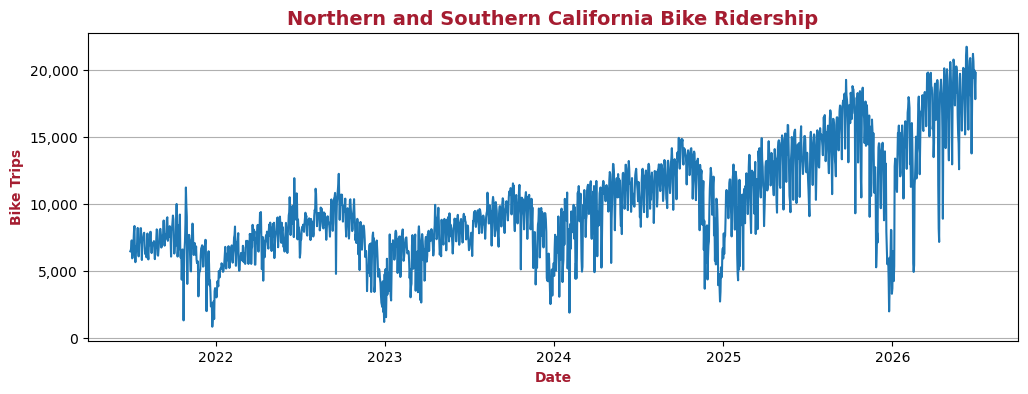

In [23]:
trips_by_date_df = bike_df\
    .groupby(['date', 'month', 'quarter'], as_index = False)\
    .agg(daily_trips = ('trip', 'sum'))

fig, ax = plt.subplots(figsize = (12, 4))
ax.set_title('Northern and Southern California Bike Ridership', fontdict = title_large_font_dict)
ax.plot(trips_by_date_df['date'], trips_by_date_df['daily_trips'])
ax.set_ylabel('Bike Trips', fontdict = axis_font_dict)
ax.set_xlabel('Date', fontdict = axis_font_dict)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, pos: f'{y:,.0f}'))
plt.grid(axis = 'y')
plt.show()

## Save Consolidated Data 
<a id="save"></a>

[Return to contents](#contents)

In [24]:
bike_df.to_pickle(data_prefix  + 'bike_data')
print('Proceed with second Notebook: Bike_Ridership_Analysis.ipynb')

Proceed with second Notebook: Bike_Ridership_Analysis.ipynb


# References:
<a id="ref"></a>

**LA County Bikeway Projects:** https://pw.lacounty.gov/tpp/bike/index.cfm?action=projects&CFID=73153822&CFTOKEN=6d74aa096542fc89-E8F5981C-BBE2-885E-EA394C55251D9130<br/>
**Southern California Data:** https://bikeshare.metro.net/about/data/<br/>
**Northern California Data:** https://lyftbikes.com/system-data<br/>
**Northern California County Boundaries:** https://data.sf.gov/Geographic-Locations-and-Boundaries/Bay-Area-Counties/s9wg-vcph<br/>

[Return to contents](#contents)